# WF4 - Complete workflow: OptimisationSimulation (ACCIM custom model)

WF4 optimises the ACCIM custom adaptive model with NSGA-II. The decision variables are the slope `m` and intercept `n` of the comfort temperature, the offset of the setpoints and their upper applicability limit; the two objectives, both minimised, are the annual HVAC electricity and the annual mean operative temperature. The m-n filter keeps every evaluated pair of `m` and `n` inside the band of published adaptive models. Compromise solutions are then chosen from the non-dominated set (knee point and TOPSIS).

The notebook follows Example 4 of the accim paper (optimisation of the custom model), with the sample building and weather files distributed with accim instead of the office building of the paper, and a smaller budget. The results are therefore similar in nature, not identical.

To keep the run light, the optimisation only keeps annual results. Afterwards, the non-dominated solutions are simulated again, keeping their hourly outputs, to screen them against ASHRAE 55 and to look at the hourly results of the compromise solutions. WF1 is the workflow that keeps the hourly results of every evaluation.

In practical terms, we will move through preparation, configuration, execution, and verification so every transition in the workflow stays explicit.
As the notebook progresses, each code cell is introduced with context first, then the call itself, and finally quick guidance on how to interpret the result.

Workflow roadmap:
- Preparation: imports, paths, optimisation budget and a lighter simulation setup (2 timesteps per hour, full-year run period).
- Configuration: outputs, objectives, parameter ranges and the m-n filter.
- Optimisation: NSGA-II with annual results, the Pareto diagram and the compromise solutions.
- Hourly analysis: the non-dominated solutions simulated again, screened against ASHRAE 55 (80 % acceptability), and the hourly results of the compromise solutions.

Main classes, methods, and functions used in this notebook:
- `OptimisationSimulation`
- `ef.get_building`
- `reduce_runtime`
- `modify_HVACmode`
- `optim.discover_available_outputs`
- `optim.select_outputs`
- `optim.apply_outputs_preflight`
- `optim.set_output_readers`
- `optim.set_parameters`
- `optim.set_problem`
- `optim.set_mn_filter`
- `optim.estimate_optimisation_sims`
- `OptimisationSimulation.run_optimisation`
- `optim.plot_parametric_scatter`
- `optim.plot_mn_filter`
- `optim.plot_best_compromise_solutions`
- `optim.plot_parallel_coordinates`
- `optim.run_parametric_simulation`
- `optim.compute_hourly_indicators`
- `optim.plot_comfort_screening`
- `optim.get_hourly_df_parametric`
- `optim.plot_adaptive_comfort_chart`
- `optim.plot_load_duration_curves`

Narrative structure used in this notebook:
- Each code cell is preceded by an explanatory markdown block.
- Section headings are contextual to the current notebook and execution block.
- Key arguments are described before they are used in code.
- Execution-oriented cells may include a follow-up markdown note to help interpret results.

## WF4 custom optimization: import workflow dependencies

We start by loading every dependency required by the full workflow, so the remaining sections can run without hidden imports.

In this complete workflow notebook, imports are intentionally grouped in one place. That makes reruns in a fresh kernel predictable and easier to debug when versions change.

The cell also defines `show_plot_output`, a small helper that displays the figures and image files returned by the plotting methods.

What to verify right after running this cell:
- Review execution output and proceed when values look consistent with the workflow intent.

In [1]:
import os
import random
from pathlib import Path

import pandas as pd
import accim
from besos import eppy_funcs as ef
from besos.objectives import MeterReader
from accim.parametric_and_optimisation.main import OptimisationSimulation
from accim.parametric_and_optimisation.funcs_for_besos.param_accis import modify_HVACmode
from accim.parametric_and_optimisation.objectives import average_results, sum_results
from accim.utils import reduce_runtime

# (Run once per notebook)
%matplotlib inline
# If you prefer interaction (zoom/pan), use: %matplotlib widget
from IPython.display import Image, display
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 160)


def show_plot_output(plot_output, image_paths=None):
    # Optional deterministic image display for methods that return tabular data.
    if image_paths is not None:
        if isinstance(image_paths, (str, Path)):
            image_paths = [image_paths]
        for plot_path in image_paths:
            display(Image(filename=str(plot_path)))

    if isinstance(plot_output, dict):
        for plot_path in plot_output.values():
            display(Image(filename=str(plot_path)))
        return
    if isinstance(plot_output, (str, Path)):
        display(Image(filename=str(plot_output)))
        return
    if hasattr(plot_output, "fig"):
        display(plot_output.fig)
        plt.show()
        return
    if hasattr(plot_output, "savefig"):
        display(plot_output)
        plt.show()
        return
    if isinstance(plot_output, pd.DataFrame):
        display(plot_output)
        return
    raise TypeError(f"Unsupported plot output type: {type(plot_output)}")


## WF4 custom optimization: set project paths, weather files and optimisation budget

Here we declare the project assets (IDF, EPWs, and results folder) and the budget of the optimisation.

The IDF and EPW files are the sample files in this folder. If accim was installed with `pip install "accim[samples]"`, copy this folder to a working directory before running the notebook, so that the installed files are not modified; the results are written to `RESULTS_DIRNAME` inside it.

Key settings in this cell and why they matter:
- `POPULATION_SIZE`: individuals per generation of NSGA-II, 20 as in the paper.
- `EVALUATIONS`: simulations per weather file. The paper used 400; 60 (three generations) keep this example short, and the value can be raised for a better-converged front.
- `SEED`: seed of the random number generator, so the same run can be repeated.
- `PROCESSES`: simulations run in parallel within each generation. Half of the logical CPUs is a safe default.

Variables created in this cell:
- `PROJECT_ROOT`: reused in subsequent workflow blocks.
- `idf_list`: reused in subsequent workflow blocks.
- `epw_list`: reused in subsequent workflow blocks.
- `cities`: names of the weather files, used to order the panels.
- `RESULTS_DIRNAME`: reused in subsequent workflow blocks.
- `POPULATION_SIZE`, `EVALUATIONS`, `SEED`, `PROCESSES`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm that the IDF and EPW files are found.

In [2]:
PROJECT_ROOT = Path.cwd()

idf_list = [
    "OSM_TestResidentialUnit_v01_onlygeometry_SchNatVent_v2520_high_performance.idf",
]
epw_list = ["Sydney.epw", "Seville.epw"]
cities = [Path(epw).stem for epw in epw_list]
RESULTS_DIRNAME = "wf4_optimisation_custom_results"

POPULATION_SIZE = 20
EVALUATIONS = 60
SEED = 20261001
PROCESSES = max(1, (os.cpu_count() or 2) // 2)

print("IDF files found:", [(PROJECT_ROOT / idf).exists() for idf in idf_list])
print("EPW files found:", [(PROJECT_ROOT / epw).exists() for epw in epw_list])
print("Parallel processes:", PROCESSES)


IDF files found: [True]
EPW files found: [True, True]
Parallel processes: 6


## WF4 custom optimization: load the baseline IDF model and make the simulations lighter

Load the base building model used by subsequent runs.

This is where the baseline IDF is loaded for all downstream operations. Later cells reuse this object for output setup, parameterization, and execution. The changes below only affect the model in memory: the IDF file is not modified.

The simulations are made lighter while keeping annual results:
- `reduce_runtime(...)` sets 2 timesteps per hour (the model has 6), minimal shadowing and a lower limit of figures in the shadow overlap calculations. Its run period arguments keep the full year: by default, `reduce_runtime` shortens the run period to 1 January.
- `Run_Simulation_for_Sizing_Periods = "No"`: the design days are still used to size the HVAC system, but they are not simulated as additional environments. Otherwise, the annual results read after each simulation would also include the 7 design days of the sample model (8,928 hours instead of 8,760), and the HVAC electricity would be about 3 % higher.

Fewer timesteps make each simulation faster, with small differences in the annual energy compared with the 6 timesteps of the model. For final results, remove the `reduce_runtime(...)` call, but keep the sizing-period setting.

Variables created in this cell:
- `building`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm that the printed messages report 2 timesteps per hour and MinimalShadowing.

In [3]:
building = ef.get_building(idf_list[0])

reduce_runtime(
    idf_object=building,
    minimal_shadowing=True,
    timesteps=2,
    runperiod_begin_month=1,
    runperiod_begin_day_of_month=1,
    runperiod_end_month=12,
    runperiod_end_day_of_month=31,
)
# Keep the design days out of the annual results.
building.idfobjects["SimulationControl"][0].Run_Simulation_for_Sizing_Periods = "No"


Solar distribution has been set to MinimalShadowing.
Shading Calculation Update Frequency was previously set to 20 days, and it has been modified to 20 days.
Maximum Figures in Shadow Overlap Calculations was previously set to 15000 days, and it has been modified to 200 days.
Number of Timesteps per Hour was previously set to 6 days, and it has been modified to 2 days.


## WF4 custom optimization: initialize optimization simulation object

Here we instantiate the optimization engine that will evaluate candidates across the configured climates.

As in Example 4 of the paper, the building is fully air-conditioned: the VRF system without natural ventilation (`ScriptType="vrf_ac"`) and `HVACmode` 0.

Key arguments used in this cell and why they matter:
- `buildings`: loaded IDF model used in this workflow.
- `parameters_type`: parameter family used in the simulation setup.
- `epws`: list of EPW weather files; the optimisation runs once per weather file.
- `output_freqs`: time frequency requested for outputs; the annual objectives are calculated from hourly values.
- `ScriptType`: `"vrf_ac"`, a VRF system for fully air-conditioned buildings.
- `modify_HVACmode(building, 0)`: fixes the operation to air conditioning only.

Variables created in this cell:
- `optim`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm these objects are available for the next block: `optim`.

In [4]:
optim = OptimisationSimulation(
    buildings=[building],
    parameters_type="accim custom model",
    epws=epw_list,
    output_freqs=["hourly"],
    ScriptType="vrf_ac",
)
modify_HVACmode(building, 0)



--------------------------------------------------------
Adaptive-Comfort-Control-Implemented Model (ACCIM) v0.7.8
--------------------------------------------------------

This tool allows to apply adaptive setpoint temperatures. 
For further information, please read the documentation: 
https://accim.readthedocs.io/en/master/
For a visual understanding of the tool, please visit the following jupyter notebooks:
-    Using addAccis() to apply adaptive setpoint temperatures
https://accim.readthedocs.io/en/master/jupyter_notebooks/addAccis/using_addAccis.html
-    Using rename_epw_files() to rename the EPWs for proper data analysis after simulation
https://accim.readthedocs.io/en/master/jupyter_notebooks/rename_epw_files/using_rename_epw_files.html
-    Using runEp() to directly run simulations with EnergyPlus
https://accim.readthedocs.io/en/master/jupyter_notebooks/runEp/using_runEp.html
-    Using the class Table() for data analysis
https://accim.readthedocs.io/en/master/jupyter_notebo

Control type schedule: Always 4 Schedule has been added
Relative humidity setpoint schedule: Always 50.00 Schedule has been added


Heating Fanger comfort setpoint: Always -0.5 Schedule has been added
Cooling Fanger comfort setpoint: Always  0.1 Schedule has been added
Zone CO2 setpoint: Always 900ppm Schedule has been added
Min CO2 concentration: Always 600ppm Schedule has been added


Generic contaminant setpoint: Always 0.5ppm Schedule has been added
Air distribution effectiveness (always 1) Schedule has been added


VRF Heating Cooling (Northern Hemisphere) Schedule has been added
DefaultFanEffRatioCurve Curve:Cubic Object has been added
VRFTUCoolCapFT Curve:Cubic Object has been added
VRFTUHeatCapFT Curve:Cubic Object has been added
VRFCoolCapFTBoundary Curve:Cubic Object has been added
VRFCoolEIRFTBoundary Curve:Cubic Object has been added
CoolingEIRLowPLR Curve:Cubic Object has been added
VRFHeatCapFTBoundary Curve:Cubic Object has been added
VRFHeatEIRFTBoundary Curve:Cubic Object has been added
HeatingEIRLowPLR Curve:Cubic Object has been added
DefaultFanPowerRatioCurve Curve:Exponent Object has been added
DXHtgCoilDefrostEIRFT Curve:Biquadratic Object has been added
VRFCoolCapFT Curve:Biquadratic Object has been added
VRFCoolCapFTHi Curve:Biquadratic Object has been added
VRFCoolEIRFT Curve:Biquadratic Object has been added
VRFCoolEIRFTHi Curve:Biquadratic Object has been added
VRFHeatCapFT Curve:Biquadratic Object has been added
VRFHeatCapFTHi Curve:Biquadratic Object has been added
VRFHeat

ACST_Sch_Floor_2_Residential_Living_Occupants Schedule has been added
Added - SetComfTemp Program
Added - CountHours_Floor_1_Residential_Living_Occupants Program
Added - CountHours_Floor_2_Residential_Living_Occupants Program
Added - SetAppLimits Program
Added - ApplyCAT Program


Added - SetAST_Master Program with 109 lines


Added - 46 per-ComfStand SetAST subprograms
Added - SetAST Program (base program that calls SetAST_Master)
Added - SetASTnoTol Program
Added - CountHoursNoApp_Floor_1_Residential_Living_Occupants Program
Added - SetGeoVarFloor_1_Residential_Living_Occupants Program
Added - CountHoursNoApp_Floor_2_Residential_Living_Occupants Program
Added - SetGeoVarFloor_2_Residential_Living_Occupants Program
Added - SetInputData Program
Added - Comfort Temperature Output Variable
Added - Adaptive Cooling Setpoint Temperature Output Variable
Added - Adaptive Heating Setpoint Temperature Output Variable
Added - Adaptive Cooling Setpoint Temperature_No Tolerance Output Variable
Added - Adaptive Heating Setpoint Temperature_No Tolerance Output Variable
Added - z_test_ComfStand Output Variable
Added - z_test_ACSTaul Output Variable
Added - z_test_ACSTall Output Variable
Added - z_test_AHSTaul Output Variable
Added - z_test_AHSTall Output Variable
Added - z_test_CAT Output Variable
Added - z_test_ACSToffse

## WF4 custom optimization: discover available outputs and select the minimal set

Before locking outputs, we scan what this model setup can actually report, and keep only the outputs the workflow uses:
- meters `Electricity:HVAC`, `Heating:Electricity` and `Cooling:Electricity`;
- `Zone Operative Temperature` of each zone;
- `Zone Thermal Comfort ASHRAE 55 Adaptive Model Running Average Outdoor Air Temperature`, for the screening of the non-dominated solutions (one People object is enough).

They are reported hourly, but the optimisation deletes the simulation files once the annual results have been read, so they only take disk space for the solutions simulated again at the end.

Key arguments used in this cell and why they matter:
- `reduce_sim_time`: enables a fast scan mode when discovering outputs.
- `prefer`: preferred backend for output discovery.
- `meters`: energy meters to include as outputs.
- `variables`: output variables to include by name.
- `match`: matching rule used to select outputs (exact names, ignoring case).
- `on_missing`: `"raise"` stops here if a requested output is not available.

Variables created in this cell:
- `meter_names`: reused in subsequent workflow blocks.
- `hourly_variable_names`: reused in subsequent workflow blocks.
- `available_outputs`: reused in subsequent workflow blocks.
- `df_meters_sel`: reused in subsequent workflow blocks.
- `df_vars_sel`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Check that three meters and the operative temperature of every zone are selected, plus one running-mean column.
- Confirm the reported discovery source matches your preferred backend.

In [5]:
meter_names = ["Electricity:HVAC", "Heating:Electricity", "Cooling:Electricity"]
hourly_variable_names = [
    "Zone Operative Temperature",
    "Zone Thermal Comfort ASHRAE 55 Adaptive Model Running Average Outdoor Air Temperature",
]
available_outputs = optim.discover_available_outputs(
    reduce_sim_time=True,
    prefer="testsimeplus",
)
print("Discovery source:", available_outputs["meta"].get("source"))

df_meters_sel = optim.select_outputs(
    meters=meter_names,
    match="case_insensitive",
    on_missing="raise",
)["meters"]
df_vars_sel = optim.select_outputs(
    variables=hourly_variable_names,
    match="case_insensitive",
    on_missing="raise",
)["variables"]

# The running mean is the same for every People object: keep the first one.
is_running_mean = df_vars_sel["variable_name"].str.contains("Running Average")
df_vars_sel = pd.concat(
    [df_vars_sel[~is_running_mean], df_vars_sel[is_running_mean].head(1)],
    ignore_index=True,
)
print(df_meters_sel[["key_name", "frequency"]].to_string(index=False))
print(df_vars_sel[["key_value", "variable_name", "frequency"]].to_string(index=False))


Solar distribution is already set to MinimalShadowing, therefore no action has been performed.
Shading Calculation Update Frequency was previously set to 20 days, and it has been modified to 20 days.
Maximum Figures in Shadow Overlap Calculations was previously set to 200 days, and it has been modified to 200 days.
Number of Timesteps per Hour was previously set to 2 days, and it has been modified to 2 days.


Discovery source: testsimeplus
           key_name frequency
   Electricity:HVAC    Hourly
Heating:Electricity    Hourly
Cooling:Electricity    Hourly
                           key_value                                                                         variable_name frequency
                        FLOOR_1_ZONE                                                            Zone Operative Temperature    Hourly
                        FLOOR_2_ZONE                                                            Zone Operative Temperature    Hourly
FLOOR_1 RESIDENTIAL LIVING OCCUPANTS Zone Thermal Comfort ASHRAE 55 Adaptive Model Running Average Outdoor Air Temperature    Hourly


## WF4 custom optimization: run output preflight checks before execution

This block applies preflight checks to the selected outputs before execution.

Preflight is the final schema gate; if this step is clean, output-related runtime errors are much less likely. With `clean_mode="all"`, the output objects of the IDF (37 output variables, the SQLite file and the summary tables of the sample model) are removed before the selection is added.

Key arguments used in this cell and why they matter:
- `df_meters_sel`: table of selected meters to apply to the IDF.
- `df_vars_sel`: table of selected variables to apply to the IDF.
- `clean_mode`: cleanup mode applied before adding outputs.
- `validate_before_apply`: whether to validate before editing the IDF.
- `validate_after_apply`: whether to validate after editing the IDF.
- `on_missing`: behavior when a requested output is missing.

Variables created in this cell:
- `preflight_report`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Verify that the verification reports no missing or extra outputs.

In [6]:
preflight_report = optim.apply_outputs_preflight(
    df_meters_sel=df_meters_sel,
    df_vars_sel=df_vars_sel,
    clean_mode="all",
    validate_before_apply=False,
    validate_after_apply=True,
    on_missing="raise",
)
print(preflight_report["verification"])


{'vars': {'expected': 3, 'actual': 3, 'missing_in_idf': [], 'extra_in_idf': [], 'by_idf': {}}, 'meters': {'expected': 3, 'actual': 3, 'missing_in_idf': [], 'extra_in_idf': [], 'by_idf': {}}}


## WF4 custom optimization: define the objectives and the reported outputs

The readers registered here are the objectives of the optimisation, as in Example 4 of the paper:
- the annual HVAC electricity (`Electricity:HVAC`, summed over the year, `sum_results`);
- the annual mean operative temperature (`average_results`) of the first zone, `FLOOR_1_ZONE`, as the paper used the operative temperature of the office zone.

The heating and cooling electricity are reported for every evaluation, but they are not objectives (`reported_outputs`, passed to `set_problem` as `add_outputs`).

Key arguments used in this cell and why they matter:
- `df_output_meter`: the meter objective, with its aggregation function in the `func` column.
- `df_output_variable`: the temperature objective, with `func` and the column name in `name`.

Variables created in this cell:
- `objective_meter`: reused in subsequent workflow blocks.
- `objective_temperature`: reused in subsequent workflow blocks.
- `reported_outputs`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm that there are two objectives and two reported outputs.

In [7]:
objective_meter = df_meters_sel[df_meters_sel["key_name"] == "Electricity:HVAC"].copy()
objective_meter["func"] = [sum_results] * len(objective_meter)

objective_temperature = df_vars_sel[df_vars_sel["variable_name"] == "Zone Operative Temperature"].head(1).copy()
objective_temperature["func"] = [average_results] * len(objective_temperature)
objective_temperature["name"] = "Annual mean operative temperature " + objective_temperature["key_value"]

optim.set_output_readers(
    df_output_meter=objective_meter,
    df_output_variable=objective_temperature,
)
reported_outputs = [
    MeterReader(key_name=name, frequency="Hourly", func=sum_results, name=name)
    for name in ["Heating:Electricity", "Cooling:Electricity"]
]
print("Objectives:", objective_meter["key_name"].tolist() + objective_temperature["name"].tolist())
print("Reported:", [reader.name for reader in reported_outputs])


Objectives: ['Electricity:HVAC', 'Annual mean operative temperature FLOOR_1_ZONE']
Reported: ['Heating:Electricity', 'Cooling:Electricity']


## WF4 custom optimization: define parameter ranges

This section defines the decision space of the optimisation, with the ranges of Example 4 of the paper (the same as in WF1).

Key arguments used in this cell and why they matter:
- `accis_params_dict`: ACCIM custom model parameters and their ranges:
  - `CustAST_m`: slope of the comfort temperature against the running mean outdoor temperature, 0 to 0.7;
  - `CustAST_n`: intercept of the comfort temperature, 5 to 22.5 °C;
  - `CustAST_ASToffset`: offset of the cooling and heating setpoints from the comfort temperature, 1 to 5 K;
  - `CustAST_ASTaul`: upper applicability limit of the running mean, 22 to 40 °C.
- `use_dflt_values`: parameters that are not varied take accim's default values; here, the lower applicability limit (`ASTall`) is 10 °C, and accim prints a warning about it.

Variables created in this cell:
- `accis_parameters`: reused in subsequent workflow blocks.
- `parameter_names`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm that the default value applied to the lower applicability limit is 10 °C.

In [8]:
accis_parameters = {
    "CustAST_m": (0.0, 0.7),
    "CustAST_n": (5.0, 22.5),
    "CustAST_ASToffset": (1.0, 5.0),
    "CustAST_ASTaul": (22.0, 40.0),
}
parameter_names = list(accis_parameters)
optim.set_parameters(accis_params_dict=accis_parameters, use_dflt_values=True)


The following parameters are not included in the parameters to be set, and have not been defined yet (i.e. the value is 0): ['ACSTall', 'AHSTall']


## WF4 custom optimization: configure problem definition

This section registers the parameters as decision variables, the two objectives (both minimised) and the reported outputs.

Key arguments used in this cell and why they matter:
- `minimize_outputs`: one flag per objective; `True` minimises it.
- `add_outputs`: outputs recorded for every evaluation without being objectives.

What to verify right after running this cell:
- Review execution output and proceed when values look consistent with the workflow intent.

In [9]:
optim.set_problem(minimize_outputs=[True, True], add_outputs=reported_outputs)


## WF4 custom optimization: restrict m and n to the band of published adaptive models

The m-n filter is the same as in WF1: the band of the 56 linear adaptive models collected by Yao et al. (2022). In an optimisation, `run_optimisation` maps the intercept `n` proposed by the algorithm onto the interval of `n` inside the band for the proposed slope `m`, so every evaluated pair lies inside the band. The results show the simulated `n`.

Key arguments of `set_mn_filter` (defaults used here):
- `offset`: `"farthest"` (bounds through the farthest models), a symmetric distance in `m` or a `(lower, upper)` tuple.
- `drop_models` and `add_models`: leave out models of the review or add others.

What to verify right after running this cell:
- Read the printed band: the regression line of `m` on `n` and the distances of the two bounds.

In [10]:
optim.set_mn_filter()


m-n filter (Yao et al. (2022), 56 linear adaptive models, R2 = 0.880): m = -0.0413 n + 1.0613; band from 0.1516 below to 0.1631 above the regression line.


## WF4 custom optimization: estimate expected simulation workload

Before launching the run, we estimate the number of simulations. NSGA-II completes the current generation before stopping, so each weather file takes `POPULATION_SIZE x ceil(EVALUATIONS / POPULATION_SIZE)` simulations.

With the lighter settings, one annual simulation of the sample model takes about 25-35 s when several run in parallel, and the generations run one after another. With the default budget (120 simulations) and 6 processes, the optimisation takes about 15 minutes.

Variables created in this cell:
- `estimated`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm that the estimated number of simulations fits the time available.

In [11]:
estimated = optim.estimate_optimisation_sims(
    evaluations=EVALUATIONS,
    population_size=POPULATION_SIZE,
    epws=epw_list,
)
print("Estimated simulations:", estimated)


Estimated simulations
  evaluations    : 60
  population_size: 20
  EPWs           : 2 (Sydney.epw, Seville.epw)
  sims per EPW   : 60  (3 generation(s) × 20)
  TOTAL          : 120
Estimated simulations: 120


## WF4 custom optimization: run NSGA-II with annual results

This cell launches the optimizer with the configured budget and returns the evaluated solutions, with the `pareto-optimal` flag computed separately for each weather file.

`keep_sim_files="none"` deletes each simulation folder once its annual results have been read (each process simulates in its own folder), so the optimisation leaves almost nothing on disk.

Key arguments used in this cell and why they matter:
- `epws`: weather files; one optimisation per weather file.
- `out_dir`: output folder for generated artifacts and results.
- `algorithm`, `population_size`, `evaluations`: NSGA-II and its budget.
- `processes`: number of parallel processes within each generation.
- `keep_df`: `"all"` keeps every evaluation in the results table, not only the non-dominated ones.
- `keep_sim_files`: `"none"` deletes the simulation folders.
- `pareto_separate_by_epw`: non-dominated solutions are identified within each weather file.

Variables created in this cell:
- `outputs_optim`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Inspect objective columns and the `pareto-optimal` status before moving to the compromise solutions.

In [12]:
random.seed(SEED)
outputs_optim = optim.run_optimisation(
    epws=epw_list,
    out_dir=RESULTS_DIRNAME,
    algorithm="NSGAII",
    population_size=POPULATION_SIZE,
    evaluations=EVALUATIONS,
    processes=PROCESSES,
    keep_df="all",
    keep_sim_files="none",
    pareto_separate_by_epw=True,
)


[m-n filter] run_optimisation: CustAST_n is mapped onto the band for each CustAST_m (m = -0.0413 n + 1.0613; 0.1516 below, 0.1631 above).
[run_optimisation] Starting optimisation (NSGAII): 2 case(s) (2 to run, 0 resumed) | ~60 sims/case (3 generation(s) x 20, evaluations=60) | ~120 sims in total | 6 process(es)


[run_optimisation] Case 1/2 started (idf=OSM_TestResidentialUnit_v01_onlygeometry_SchNatVent_v2520_high_performance, epw=Sydney); ~60 simulation(s) expected.


[run_optimisation] Case 1/2 | generation 1: evaluating 20 individual(s)...


[run_optimisation] Case 1/2 | gen 1 sim 1/20 | case 1/~60 | total 1/~120 (0.8%) | elapsed 0:00:32 | ETA ~1:03:12


[run_optimisation] Case 1/2 | gen 1 sim 2/20 | case 2/~60 | total 2/~120 (1.7%) | elapsed 0:00:33 | ETA ~0:32:21


...

[run_optimisation] Case 2/2 | gen 3 sim 18/20 | case 58/~60 | total 118/~120 (98.3%) | elapsed 0:05:10 | ETA ~0:00:05


[run_optimisation] Case 2/2 | gen 3 sim 19/20 | case 59/~60 | total 119/~120 (99.2%) | elapsed 0:05:16 | ETA ~0:00:03


[run_optimisation] Case 2/2 | gen 3 sim 20/20 | case 60/~60 | total 120/~120 (100.0%) | elapsed 0:05:17 | ETA ~0:00:00


[run_optimisation] Case 2/2 completed (idf=OSM_TestResidentialUnit_v01_onlygeometry_SchNatVent_v2520_high_performance, epw=Seville): 60 simulation(s), 3 generation(s) in 0:02:08.


  [info] simulation_summary updated for optimisation after run_optimisation.


### Reading the result

Inspect objective columns and `pareto-optimal` status before moving to compromise or robustness analysis.

## WF4 custom optimization: preview execution outputs and row counts

We perform a quick sanity check on row counts, the number of non-dominated solutions per weather file and the size of the results folder.

What to verify right after running this cell:
- Confirm the number of evaluations per weather file and that each one has several non-dominated solutions.

In [13]:
print("Rows:", len(outputs_optim))
display(outputs_optim.groupby("epw")["pareto-optimal"].agg(evaluations="size", non_dominated="sum"))

results_mb = sum(p.stat().st_size for p in Path(RESULTS_DIRNAME).rglob("*") if p.is_file()) / 1e6
print(f"Results folder: {results_mb:.1f} MB")


Rows: 120


,evaluations,non_dominated
epw,,
Seville,60,13
Sydney,60,11


Results folder: 1.2 MB


## WF4 custom optimization: normalize datasets and collect the result columns

In this stage we convert the annual energy to kWh per m2 of floor area and identify the objective columns used in the plots.

Key arguments used in this cell and why they matter:
- `mode`: `"all"` uses the floor area of every zone of the IDF.
- `df_types`: dataset groups that should be normalized.

Variables created in this cell:
- `main_energy_col`: the HVAC electricity objective.
- `temperature_col`: the annual mean operative temperature objective.
- `plot_out_dir`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm the floor area and the two objective columns.

In [14]:
optim.set_building_floor_area(mode="all")
optim.normalize_outputs(df_types=["optimisation"])

results_optim = optim.outputs_optimisation
main_energy_col = next(c for c in results_optim.columns if "Electricity:HVAC" in c)
temperature_col = next(c for c in results_optim.columns if c.startswith("Annual mean operative temperature"))
print(main_energy_col, "|", temperature_col)

plot_out_dir = Path(RESULTS_DIRNAME) / "plots"
plot_out_dir.mkdir(parents=True, exist_ok=True)


  [info] Floor area calculation: total IDFs=1, representative IDFs loaded=1.
  [info] Floor area mapping coverage: 1/1 IDFs.
  [info] Building floor area: 185.81 m² (single IDF)
  [info] Normalized 3 energy columns in outputs_optimisation.
Electricity:HVAC_kWh/m2 | Annual mean operative temperature FLOOR_1_ZONE


## WF4 custom optimization: Pareto diagram

The two objectives of every evaluation, one panel per weather file, with the non-dominated solutions marked (`style="pareto-optimal"`) and the colour giving the offset of the setpoints. Lower HVAC electricity comes with a higher annual mean operative temperature: the front shows how much of one has to be given up to improve the other.

Key arguments used in this cell and why they matter:
- `x`, `y`: the two objectives.
- `hue`: offset of the setpoints.
- `style`: non-dominated or dominated.
- `col`: one panel per weather file.

Variables created in this cell:
- `fig_pareto`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Check that the non-dominated solutions form the lower-left edge of each cloud of points.

  Parametric scatter plot saved: wf4_optimisation_custom_results\plots\plot_parametric_scatter_optimisation_Electricity_HVAC_kWh_m2_vs_Annual_mean_operative_temperature_FLOOR_1_ZONE.png


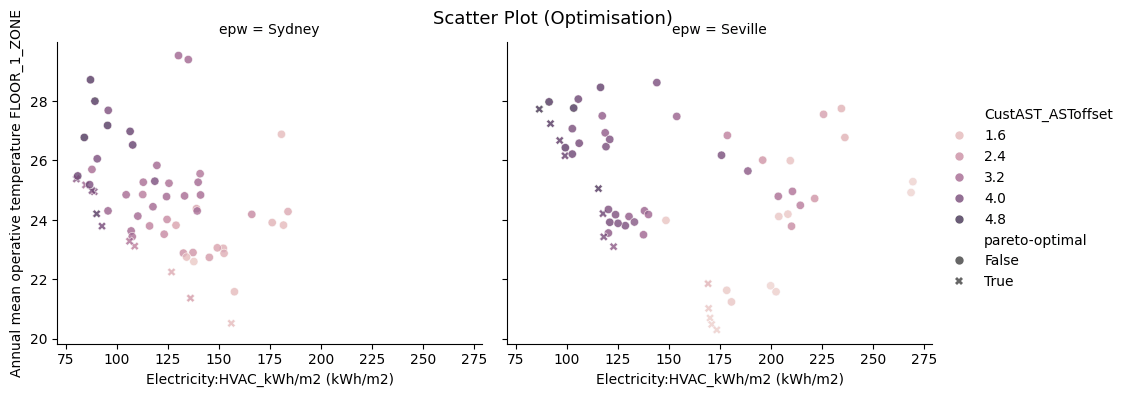

In [15]:
fig_pareto = optim.plot_parametric_scatter(
    x=main_energy_col,
    y=temperature_col,
    df_source="optimisation",
    hue="CustAST_ASToffset",
    style="pareto-optimal",
    col="epw",
    out_dir=str(plot_out_dir),
    normalize_per_m2=False,
)
show_plot_output(fig_pareto)


### Reading the result

Open saved figures and verify that filters, grouping, and labels match your intended interpretation.

## WF4 custom optimization: plot the m-n band and the evaluated pairs

The evaluated pairs of `m` and `n` lie inside the band of published adaptive models, as the m-n filter maps the proposed `n` onto it.

Key arguments used in this cell and why they matter:
- `df_source`: `"optimisation"` draws the pairs of the evaluations.
- `out_dir`: output folder for the figure.

What to verify right after running this cell:
- Confirm that every evaluated pair lies inside the band.

  m-n filter plot saved: wf4_optimisation_custom_results\plots\plot_mn_filter_optimisation.png (120 included and 0 excluded combinations, 56 models)


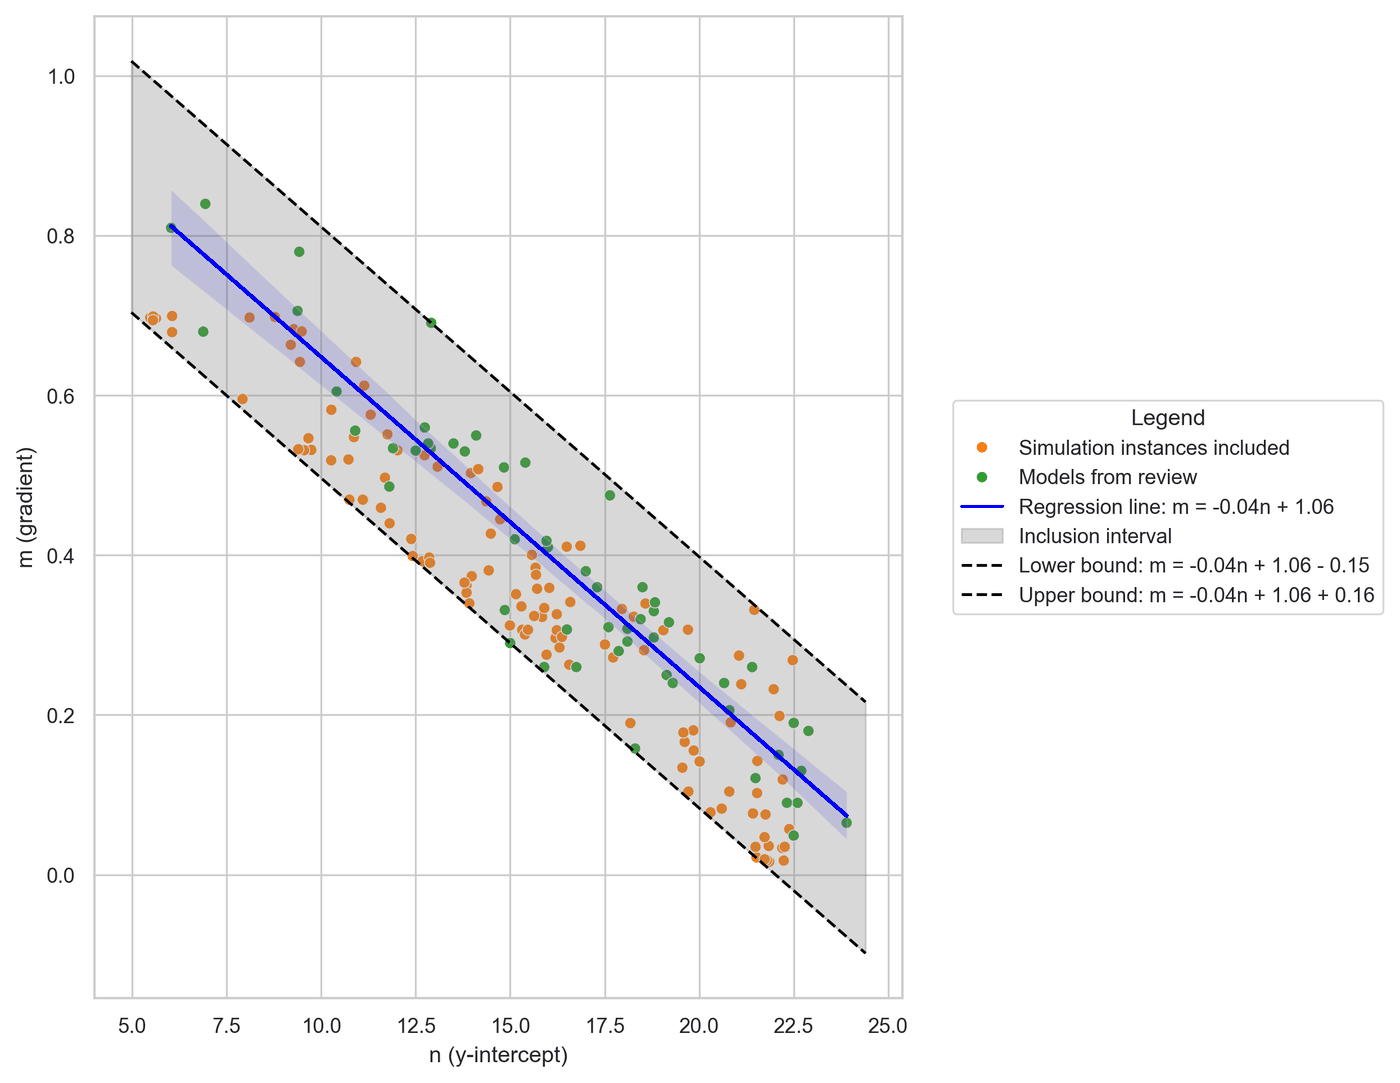

In [16]:
show_plot_output(optim.plot_mn_filter(df_source="optimisation", out_dir=str(plot_out_dir)))


### Reading the result

Open saved figures and verify that filters, grouping, and labels match your intended interpretation.

## WF4 custom optimization: choose compromise solutions

`plot_best_compromise_solutions` chooses solutions from the non-dominated set of each weather file with three methods:
- knee point: the solution closest to the utopia point (the best value of each objective) after min-max normalisation of the objectives;
- TOPSIS with equal weights: the solution closest to the ideal and farthest from the anti-ideal solution, after normalising each objective by its vector norm. With these objectives it tends to the lowest-energy end of the front;
- TOPSIS with weights 0.7 and 0.3 for the HVAC electricity and the operative temperature.

The figure draws the two objectives of the non-dominated (blue) and dominated (grey) solutions, with the chosen ones marked: the horizontal axis is the HVAC electricity and the vertical one the annual mean operative temperature (°C), although the label of that axis repeats the energy unit.

Key arguments used in this cell and why they matter:
- `out_dir`: folder of the figure and of `results_mcdm_best_solutions.csv`.

Variables created in this cell:
- `mcdm`: one row per weather file and method.
- `selection_labels`: labels of the methods.

What to verify right after running this cell:
- Compare the parameters and objectives of the solutions chosen by each method.


  [epw=Sydney] Best compromise solutions:
    knee_point                | Electricity:HVAC_kWh/m2=108.8 kWh/m2 | Annual mean operative temperature FLOOR_1_ZONE=23.1 kWh/m2
    topsis                    | Electricity:HVAC_kWh/m2=80.3 kWh/m2 | Annual mean operative temperature FLOOR_1_ZONE=25.4 kWh/m2
    topsis_w70_30             | Electricity:HVAC_kWh/m2=80.3 kWh/m2 | Annual mean operative temperature FLOOR_1_ZONE=25.4 kWh/m2

  [epw=Seville] Best compromise solutions:
    knee_point                | Electricity:HVAC_kWh/m2=118.2 kWh/m2 | Annual mean operative temperature FLOOR_1_ZONE=23.4 kWh/m2
    topsis                    | Electricity:HVAC_kWh/m2=99.2 kWh/m2 | Annual mean operative temperature FLOOR_1_ZONE=26.2 kWh/m2
    topsis_w70_30             | Electricity:HVAC_kWh/m2=86.7 kWh/m2 | Annual mean operative temperature FLOOR_1_ZONE=27.7 kWh/m2

  MCDM summary saved: wf4_optimisation_custom_results\plots\results_mcdm_best_solutions.csv


  MCDM plot saved: wf4_optimisation_custom_results\plots\plot_mcdm_best_solutions.png


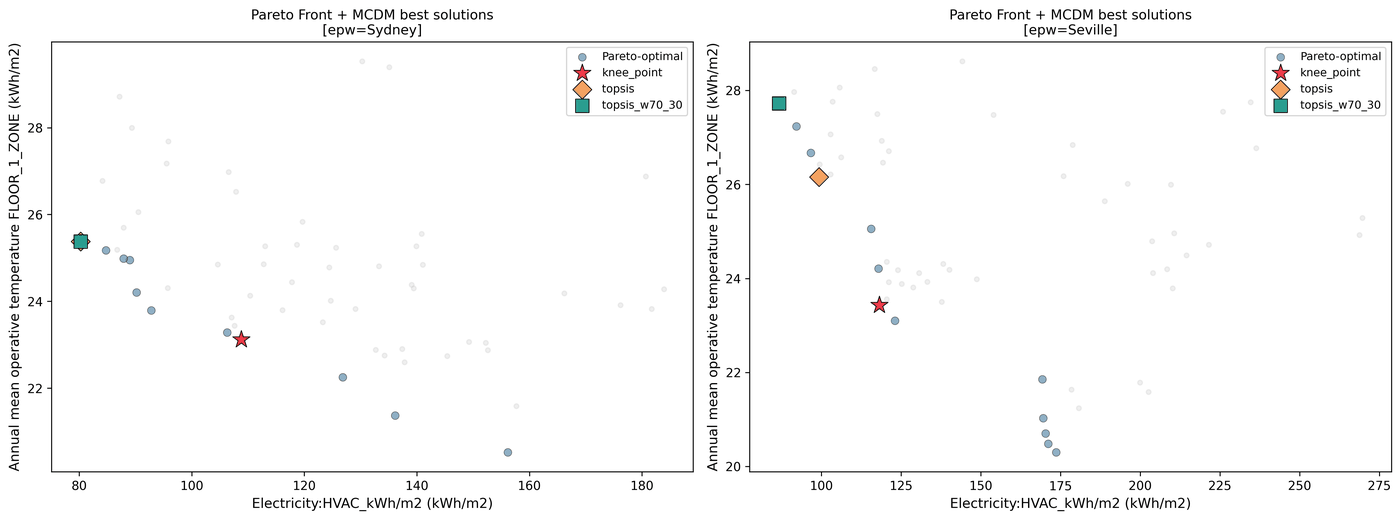

,selection,epw,CustAST_m,CustAST_n,CustAST_ASToffset,CustAST_ASTaul,Electricity:HVAC_kWh/m2,Annual mean operative temperature FLOOR_1_ZONE
0,Knee point,Sydney,0.548,10.865,2.766,38.119,108.817,23.119
1,"TOPSIS, equal weights",Sydney,0.525,12.735,3.672,37.765,80.255,25.378
2,"TOPSIS, 0.7 / 0.3",Sydney,0.525,12.735,3.672,37.765,80.255,25.378
3,Knee point,Seville,0.697,5.630,3.998,36.350,118.191,23.431
4,"TOPSIS, equal weights",Seville,0.698,8.105,4.310,35.547,99.236,26.160
5,"TOPSIS, 0.7 / 0.3",Seville,0.680,9.486,4.974,33.937,86.655,27.727


In [17]:
mcdm = optim.plot_best_compromise_solutions(out_dir=str(plot_out_dir))
show_plot_output(plot_out_dir / "plot_mcdm_best_solutions.png")

selection_labels = {
    "knee_point": "Knee point",
    "topsis": "TOPSIS, equal weights",
    "topsis_w70_30": "TOPSIS, 0.7 / 0.3",
}
mcdm["selection"] = mcdm["mcdm_method"].map(selection_labels)
mcdm[["selection", "epw"] + parameter_names + [main_energy_col, temperature_col]].round(3)


### Reading the result

Open saved figures and verify that filters, grouping, and labels match your intended interpretation.

## WF4 custom optimization: generate parallel-coordinates overview

This block generates parallel-coordinates plots to inspect the parameters and objectives of all the evaluations at once.

What to verify right after running this cell:
- Look for the parameter ranges of the non-dominated solutions.

  Parallel coordinates plot saved: wf4_optimisation_custom_results\plots\plot_parallel_coordinates_Sydney.png


  Parallel coordinates plot saved: wf4_optimisation_custom_results\plots\plot_parallel_coordinates_Seville.png


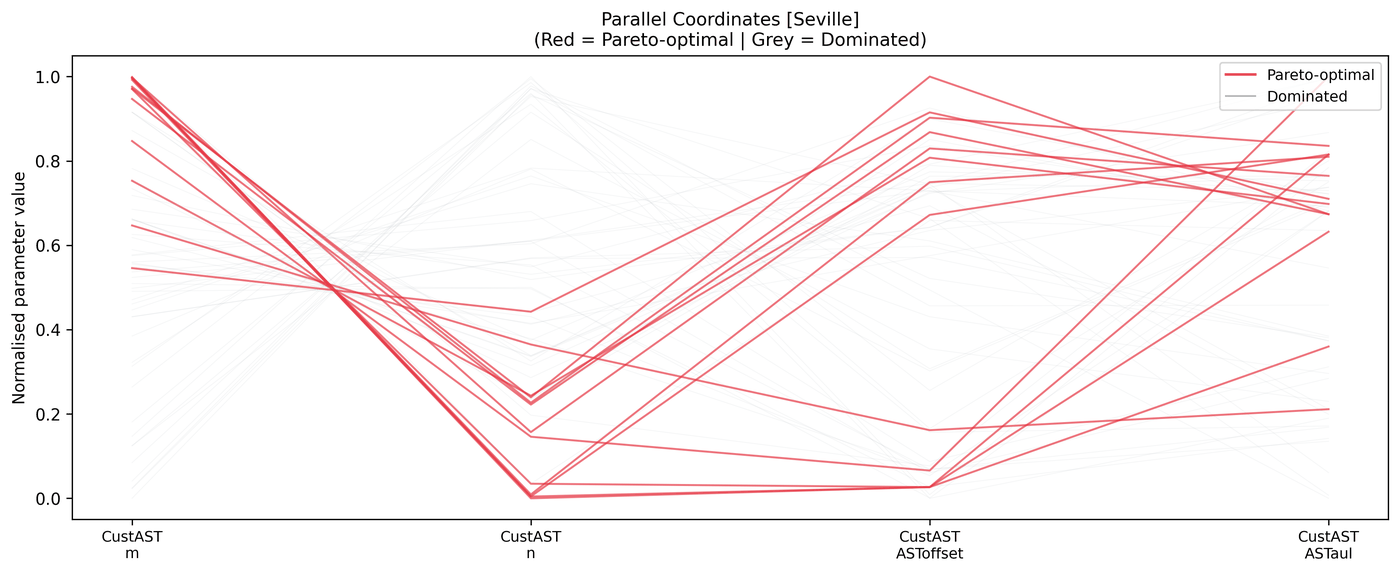

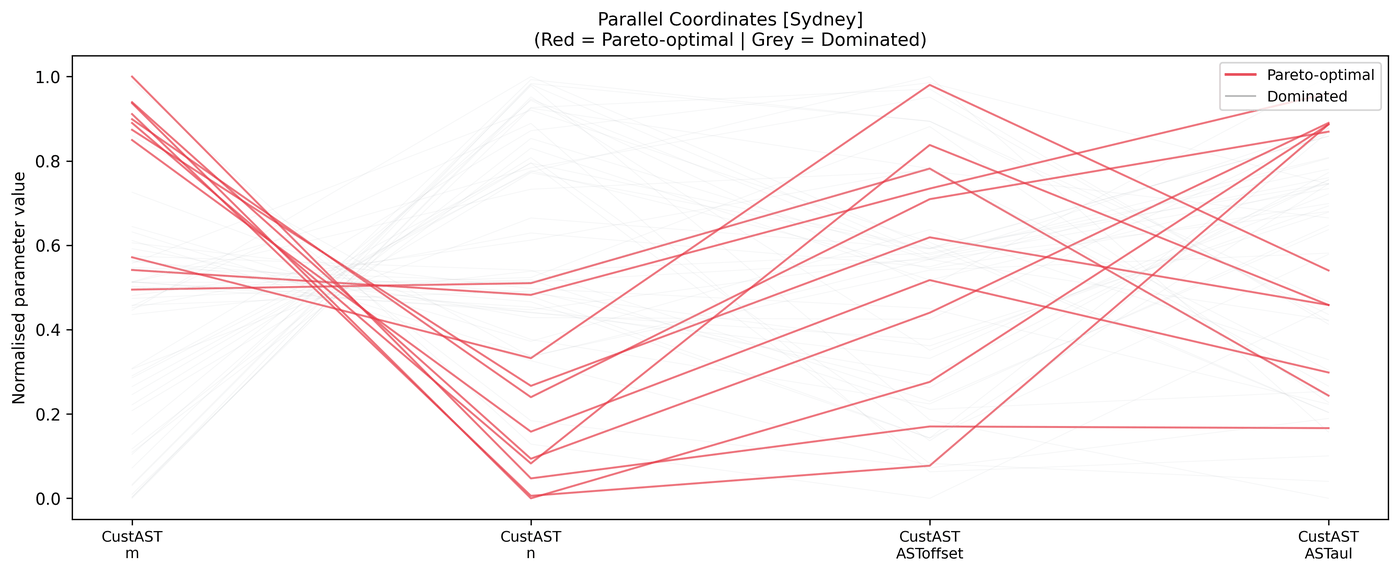

In [18]:
optim.plot_parallel_coordinates(out_dir=str(plot_out_dir))
for plot_path in sorted(plot_out_dir.glob("plot_parallel_coordinates_*.png")):
    show_plot_output(plot_path)


### Reading the result

Open saved figures and verify that filters, grouping, and labels match your intended interpretation.

## WF4 custom optimization: simulate the non-dominated solutions again with hourly outputs

The screening and the hourly views need hourly files, which the optimisation did not keep. Instead of keeping them for every evaluation, the non-dominated solutions of each weather file (which include the compromise solutions) are simulated again, keeping their hourly CSV files. The same `optim` object runs them as a parametric simulation, so the model and the outputs are the same as in the optimisation, and the annual results are reproduced; the cell checks it for the HVAC electricity.

The optimisation results are kept in `annual_optim` and saved to a CSV file. The compromise solutions have to be chosen before this cell, because the parametric run replaces the last run of `optim`.

Key arguments used in this cell and why they matter:
- `df`: the parameters of the non-dominated solutions, with the EPW file of each one.
- `out_dir`: a subfolder of the results folder.
- `keep_dirs`, `sim_files_extensions` and `sim_files_policy`: keep only the CSV and ERR files of each simulation; the loop after the run deletes `eplusmtr.csv`, a CSV file with the same meters that EnergyPlus writes alongside `eplusout.csv`.

Variables created in this cell:
- `annual_optim`: reused in subsequent workflow blocks.
- `hourly_plan`: reused in subsequent workflow blocks.
- `hourly_dir`: reused in subsequent workflow blocks.
- `hourly_outputs`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm the number of solutions simulated again and that the largest difference in HVAC electricity is close to 0.

In [19]:
annual_optim = optim.outputs_optimisation.copy()
annual_optim.to_csv(Path(RESULTS_DIRNAME) / "optimisation_results_kWh_m2.csv", index=False)

epw_files = {Path(epw).stem: epw for epw in epw_list}
key_cols = parameter_names + ["epw"]
non_dominated = annual_optim[annual_optim["pareto-optimal"].astype(bool)].drop_duplicates(subset=key_cols)
hourly_plan = non_dominated[parameter_names].assign(epw=non_dominated["epw"].map(epw_files)).reset_index(drop=True)
print("Non-dominated solutions simulated again with hourly outputs:", len(hourly_plan))

hourly_dir = Path(RESULTS_DIRNAME) / "hourly"
hourly_outputs = optim.run_parametric_simulation(
    out_dir=str(hourly_dir),
    df=hourly_plan,
    processes=PROCESSES,
    keep_input=True,
    keep_dirs=True,
    sim_files_extensions=[".csv", ".err"],
    sim_files_policy="keep",
)
for meter_csv in hourly_dir.rglob("eplusmtr.csv"):
    meter_csv.unlink()

floor_area = optim.building_floor_area
floor_area = list(floor_area.values())[0] if isinstance(floor_area, dict) else floor_area
rerun_hvac = hourly_outputs.set_index(key_cols)["Electricity:HVAC"] / 3.6e6 / floor_area
annual_hvac = non_dominated.set_index(key_cols)[main_energy_col].reindex(rerun_hvac.index)
print(f"Largest difference in HVAC electricity: {(rerun_hvac - annual_hvac).abs().max():.4f} kWh/m2")

hourly_mb = sum(p.stat().st_size for p in hourly_dir.rglob("*") if p.is_file()) / 1e6
print(f"Hourly results folder: {hourly_mb:.1f} MB")


Non-dominated solutions simulated again with hourly outputs: 24


  [info] simulation_summary updated for parametric after run_parametric_simulation.
Largest difference in HVAC electricity: 0.0000 kWh/m2
Hourly results folder: 25.4 MB


### Reading the result

The hourly run reproduces the annual results of the non-dominated solutions, so the screening below describes the same simulations as the Pareto diagram.

## WF4 custom optimization: screen the non-dominated solutions against ASHRAE 55

The comfort screening of WF1 is applied to the non-dominated solutions, with the same criterion (as in the paper):
- band: 0.31 Trm + 17.8 °C ± 3.5 K (ASHRAE 55, 80 % acceptability), with the running mean Trm reported by EnergyPlus (`running_mean="auto"`);
- outside the applicability range of Trm (10-33.5 °C), the limits of the nearest applicable Trm are kept (`applicability="clip"`);
- a solution meets the criterion when at most 5 % of the hours of the year are outside the band; otherwise it is "too warm" or "too cool".

The screening plot draws the HVAC electricity of each non-dominated solution against its share of hours outside the band, one panel per weather file, with the compromise solutions marked. The comfort criterion is not part of the optimisation, so it shows whether the compromise solutions would also meet a published comfort criterion.

Key arguments used in this cell and why they matter:
- `df_source`: `"parametric"`, the run that simulated the non-dominated solutions again.
- `selections`: `{label: rows}` of the compromise solutions, matched to the screened solutions by their parameters and weather file.
- `selection_markers`: marker of each selection.
- `threshold`: tolerance of the share of hours outside the band (0.05 = 5 %).

Variables created in this cell:
- `ASHRAE55_SCREENING`: reused in subsequent workflow blocks.
- `indicators`: one row per non-dominated solution.
- `selections`: reused in subsequent workflow blocks.
- `fig_screening`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Check whether the compromise solutions meet the 5 % tolerance.

  [compute_hourly_indicators] 24/24 simulations


comfort_outcome,meets,too cool,too warm
epw,,,
Seville,0,9,4
Sydney,9,2,0


  plot_comfort_screening saved: wf4_optimisation_custom_results\plots\plot_comfort_screening_non_dominated.png


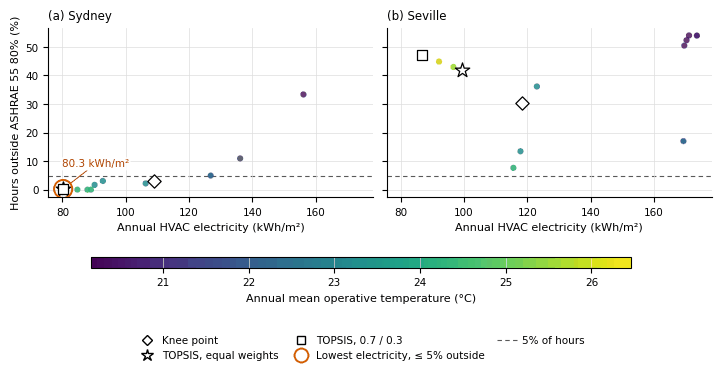

,row,col,n,Knee point_share_outside_80,Knee point_E_HVAC,"TOPSIS, equal weights_share_outside_80","TOPSIS, equal weights_E_HVAC","TOPSIS, 0.7 / 0.3_share_outside_80","TOPSIS, 0.7 / 0.3_E_HVAC",n_meeting,best_x,best_y,best_index
0,all,Sydney,11,[0.03047945205479452],[108.81706308293897],[0.0029680365296803654],[80.2550575042148],[0.0029680365296803654],[80.2550575042148],9,80.255058,0.002968,2.0
1,all,Seville,13,[0.30525114155251143],[118.19070180322922],[0.4197488584474886],[99.23623044074299],[0.47157534246575344],[86.65477698673062],0,NaN,NaN,NaN


In [20]:
ASHRAE55_SCREENING = dict(
    comfort_standard="ASHRAE55",
    categories=["80"],
    outcome_category="80",
    running_mean="auto",
    applicability="clip",
    max_share_outside=0.05,
)
indicators = optim.compute_hourly_indicators(df_source="parametric", **ASHRAE55_SCREENING)
display(indicators.groupby("epw")["comfort_outcome"].value_counts().unstack(fill_value=0))

selections = {label: rows for label, rows in mcdm.groupby("selection", sort=False)}
fig_screening = optim.plot_comfort_screening(
    df=indicators,
    x="E_HVAC",
    y="share_outside_80",
    color="T_mean",
    col="epw",
    col_order=cities,
    selections=selections,
    selection_markers={
        "Knee point": {"marker": "D"},
        "TOPSIS, equal weights": {"marker": "*", "s": 120},
        "TOPSIS, 0.7 / 0.3": {"marker": "s"},
    },
    match_on=key_cols,
    threshold=0.05,
    xlabel="Annual HVAC electricity (kWh/m²)",
    ylabel="Hours outside ASHRAE 55 80% (%)",
    color_label="Annual mean operative temperature (°C)",
    best_format="{x:.1f} kWh/m²",
    best_legend_label="Lowest electricity, ≤ 5% outside",
    out_dir=str(plot_out_dir),
    filename="plot_comfort_screening_non_dominated.png",
)
show_plot_output(fig_screening)
display(fig_screening.summary)


### Reading the result

All the points are non-dominated solutions. The summary gives, for each weather file, how many of them meet the tolerance, the lowest HVAC electricity among those that do, and the share of hours outside the band of each compromise solution.

## WF4 custom optimization: hourly results of the compromise solutions

Finally, the hourly outputs of the knee point and of the TOPSIS solution with equal weights are read, and two hourly views are drawn:
- the adaptive comfort chart: the hourly operative temperature against the running mean, with the limits of the ASHRAE 55 80 % band, one row per solution and one column per weather file;
- the load-duration curves of the HVAC electricity, one panel per solution.

Key arguments used in this cell and why they matter:
- `simulation_indices`: rows of the results table expanded to hourly values.
- `output_columns`: hourly columns read from the CSV files (names or substrings).
- `row`, `col` (comfort chart) and `panel`, `hue` (load-duration curves): grouping by solution and weather file.

Variables created in this cell:
- `hourly_selected`: reused in subsequent workflow blocks.
- `fig_comfort`: reused in subsequent workflow blocks.
- `fig_duration`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Compare the hours outside the band and the HVAC peaks of the two solutions.

[get_hourly_df_parametric] Expanding...
  Simulations selected : 2
  Hourly steps per sim : 8760
  Hourly output columns: 4  -> ['FLOOR_2_ZONE:Zone Operative Temperature [C](Hourly)', 'Electricity:HVAC [J](Hourly)', 'FLOOR_1_ZONE:Zone Operative Temperature [C](Hourly)', 'FLOOR_1 RESIDENTIAL LIVING OCCUPANTS:Zone Thermal Comfort ASHRAE 55 Adaptive Model Running Average Outdoor Air Temperature [C](Hourly)']
  Source              : csv
  Expanded shape       : ~17,520 rows x 12 cols
  Approx. memory       : ~1.7 MB
[get_hourly_df_parametric] Expanding...
  Simulations selected : 2
  Hourly steps per sim : 8760
  Hourly output columns: 4  -> ['FLOOR_2_ZONE:Zone Operative Temperature [C](Hourly)', 'Electricity:HVAC [J](Hourly)', 'FLOOR_1_ZONE:Zone Operative Temperature [C](Hourly)', 'FLOOR_1 RESIDENTIAL LIVING OCCUPANTS:Zone Thermal Comfort ASHRAE 55 Adaptive Model Running Average Outdoor Air Temperature [C](Hourly)']
  Source              : csv
  Expanded shape       : ~17,520 rows x 12 co

  plot_adaptive_comfort_chart saved: wf4_optimisation_custom_results\plots\plot_adaptive_comfort_chart_compromise.png


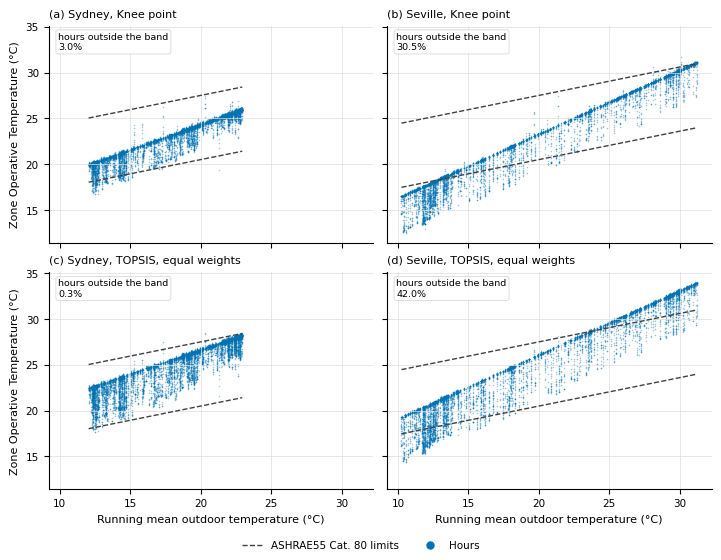

  plot_load_duration_curves saved: wf4_optimisation_custom_results\plots\plot_load_duration_curves_compromise.png


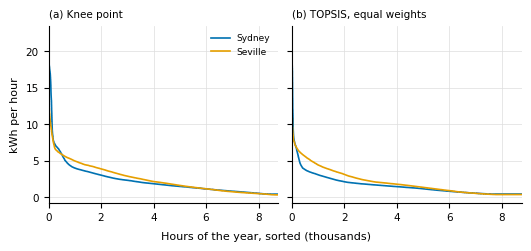

In [21]:
results_table = optim.outputs_param_simulation.reset_index()
hourly_frames = []
for label in ["Knee point", "TOPSIS, equal weights"]:
    rows = results_table.merge(selections[label][key_cols], on=key_cols)
    optim.get_hourly_df_parametric(
        simulation_indices=rows["index"].tolist(),
        output_columns=["Zone Operative Temperature", "Electricity:HVAC", "ASHRAE 55 Adaptive Model Running Average"],
        skip_confirmation=True,
    )
    hourly_frames.append(optim.outputs_param_simulation_hourly.assign(selection=label))
hourly_selected = pd.concat(hourly_frames, ignore_index=True)

fig_comfort = optim.plot_adaptive_comfort_chart(
    df=hourly_selected,
    row="selection",
    col="epw",
    col_order=cities,
    comfort_standard="ASHRAE55",
    category="80",
    applicability="clip",
    out_dir=str(plot_out_dir),
    filename="plot_adaptive_comfort_chart_compromise.png",
)
show_plot_output(fig_comfort)

fig_duration = optim.plot_load_duration_curves(
    "Electricity:HVAC",
    df=hourly_selected,
    panel="selection",
    hue="epw",
    hue_order=cities,
    out_dir=str(plot_out_dir),
    filename="plot_load_duration_curves_compromise.png",
)
show_plot_output(fig_duration)


### Reading the result

Points above the upper dashed line are too warm and points below the lower one too cool. In the load-duration curves, the left end gives the hourly peak of the HVAC electricity and the area under each curve its annual value.